In [133]:
import sys
sys.path.append("..")

from src.data_cleaning import X, y

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import numpy

import torch
from torch import nn 
from torch.utils.data import TensorDataset, DataLoader
from torch import cuda

import matplotlib.pyplot as plt

In [134]:
RANDOM_STATE = 42
BATCH_SIZE = 16
DROPOUT = 0.3
LEARNING_RATE = 1e-4
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-2
EPOCHS=2000


device = "cuda" if cuda.is_available() else "cpu"
print(f"Current device: {device}")

Current device: cpu


In [135]:
scaler = StandardScaler()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = torch.tensor(X_train, dtype=torch.float32, device=device)
y_train = torch.tensor(y_train.to_numpy(), dtype=torch.long, device=device)
X_test = torch.tensor(X_test, dtype=torch.float32, device=device)
y_test = torch.tensor(y_test.to_numpy(), dtype=torch.long, device=device)

in_features = X_train.shape[1]
out_features = len(torch.unique(y_train))

train_dataset = TensorDataset(X_train, y_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

In [ ]:
class MLP(nn.Module) :
    
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(in_features, 64, device=device)
        self.layer2 = nn.Linear(64, 64, device=device)
        self.layer3 = nn.Linear(64, out_features, device=device)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=DROPOUT)

    def forward(self, x):
        x = self.relu(self.layer1(x))
        x = self.dropout(x)
        x = self.relu(self.layer2(x))
        x = self.dropout(x)
        x = self.layer3(x)
        return x

In [137]:
mlp_model = MLP()
optimizer = torch.optim.SGD(params=mlp_model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
criterion = nn.CrossEntropyLoss()

def accuracy(y_pred, y_true):
    return (y_pred == y_true).float().mean()

In [138]:
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

for epoch in range(1, EPOCHS+1):

    mlp_model.train()
    mean_train_loss = 0
    mean_train_acc = 0
    mean_test_loss = 0
    mean_test_acc = 0
    
    for X, y in train_loader :

        y_pred = mlp_model(X)

        train_loss = criterion(y_pred, y)
        mean_train_loss += train_loss.item() * X.shape[0]/X_train.shape[0]

        y_pred_class = torch.argmax(y_pred, dim=1)
        train_acc = accuracy(y_pred_class, y)
        mean_train_acc += train_acc.item() * X.shape[0]/X_train.shape[0]


        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()


    mlp_model.eval()

    with torch.no_grad() :
        
        y_pred = mlp_model(X_test)

        test_loss = criterion(y_pred, y_test).item()

        y_pred_class = torch.argmax(y_pred, dim=1)
        test_acc = accuracy(y_pred_class, y_test).item()
    
    if epoch%50 == 0:

        train_losses.append(mean_train_loss)
        test_losses.append(test_loss)
        train_accuracies.append(mean_train_acc)
        test_accuracies.append(test_acc)

        print(f"Epoch={epoch}")
        print(f"Train loss: {mean_train_loss}; Train accuracy: {mean_train_acc}")
        print(f"Test loss: {test_loss}; Test accuracy: {test_acc}")
        print("")

Epoch=50
Train loss: 1.352896364932322; Train accuracy: 0.5400843896946323
Test loss: 1.3519287109375; Test accuracy: 0.5333333611488342

Epoch=100
Train loss: 1.2242429900269973; Train accuracy: 0.5400843883114022
Test loss: 1.1951096057891846; Test accuracy: 0.5333333611488342

Epoch=150
Train loss: 1.132164042710252; Train accuracy: 0.5400843896946322
Test loss: 1.1074672937393188; Test accuracy: 0.5333333611488342

Epoch=200
Train loss: 1.104886622368535; Train accuracy: 0.5485232082600331
Test loss: 1.052823781967163; Test accuracy: 0.5333333611488342

Epoch=250
Train loss: 1.0677210791704523; Train accuracy: 0.556962026825434
Test loss: 1.0141834020614624; Test accuracy: 0.5333333611488342

Epoch=300
Train loss: 1.035045132355348; Train accuracy: 0.569620253919046
Test loss: 0.9839252233505249; Test accuracy: 0.5333333611488342

Epoch=350
Train loss: 1.0317329902689165; Train accuracy: 0.5949367101182415
Test loss: 0.9596602320671082; Test accuracy: 0.550000011920929

Epoch=400
T

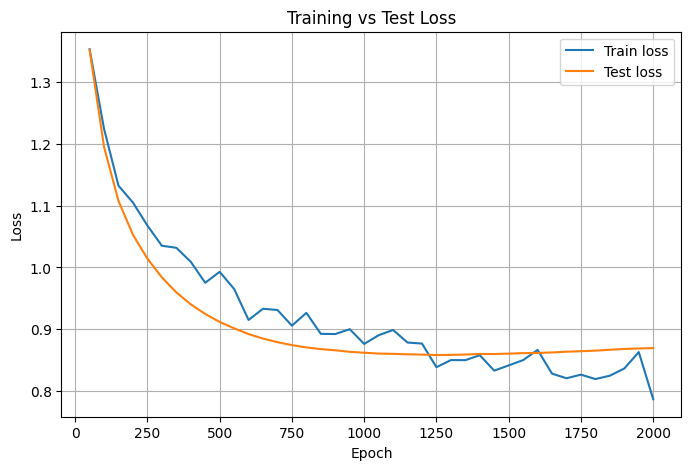

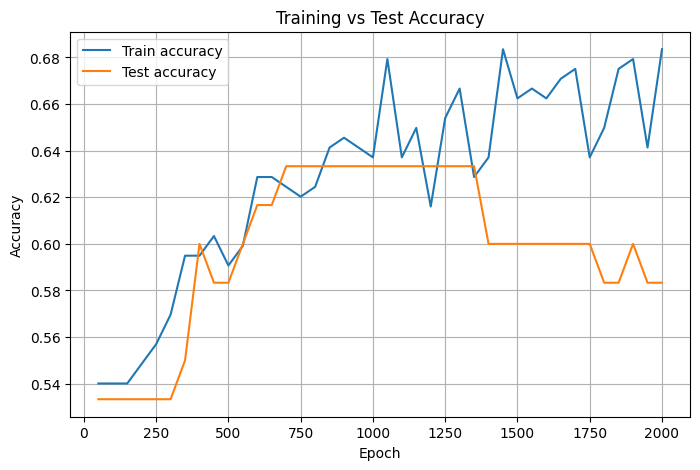

In [139]:
import matplotlib.pyplot as plt

epochs = range(50, EPOCHS + 1, 50)

# Graphe 1 : Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, test_losses, label="Test loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Test Loss")
plt.legend()
plt.grid(True)
plt.show()

# Graphe 2 : Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accuracies, label="Train accuracy")
plt.plot(epochs, test_accuracies, label="Test accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Test Accuracy")
plt.legend()
plt.grid(True)
plt.show()